In [ ]:
!pip -q install datasets

In [ ]:
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from PIL import Image

%matplotlib inline

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


In [ ]:
dataset = load_dataset("AI-Lab-Makerere/beans")

print(dataset)
print("Train samples:", len(dataset["train"]))
print("Validation samples:", len(dataset["validation"]))
print("Test samples:", len(dataset["test"]))

label_names = dataset["train"].features["labels"].names
num_classes = len(label_names)
print("Classes and indices:", {name: i for i, name in enumerate(label_names)})

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
Train samples: 1034
Validation samples: 133
Test samples: 128
Classes and indices: {'angular_leaf_spot': 0, 'bean_rust': 1, 'healthy': 2}


In [ ]:
size = 32

train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to model input size
    transforms.RandomHorizontalFlip(),     # horizontal flip augmentation
    transforms.RandomRotation(15),          # rotate ±15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()                   # convert PIL to tensor
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

class BeansDataset(Dataset):
    def __init__(self, hf_dataset, transform):
        self.data = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        image = self.data[index]["image"].convert("RGB")
        label = int(self.data[index]["labels"])
        image = self.transform(image)
        return image, label

train_data = BeansDataset(dataset["train"], transform=train_transform)
val_data = BeansDataset(dataset["validation"], transform=val_transform)
test_data = BeansDataset(dataset["test"], transform=val_transform)

In [ ]:
print("Dataset Summary")
print("Train Data: ", len(train_data))
print("Validation Data: ", len(val_data))
print("Test Data: ", len(test_data))
print("Classes and Indices: ", {name: i for i, name in enumerate(label_names)})

Dataset Summary
Train Data:  1034
Validation Data:  133
Test Data:  128
Classes and Indices:  {'angular_leaf_spot': 0, 'bean_rust': 1, 'healthy': 2}


In [ ]:
batch_size = 32
learning_rate = 1e-3
epoch_number = 10

In [ ]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

In [ ]:
from torch.optim import SGD, Adam

def get_model():
    model = nn.Sequential(
        # Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier
        nn.Flatten(),
        nn.Linear(128*6*6, 256),
        nn.ReLU(),
        nn.Linear(256, num_classes)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [ ]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)


@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [ ]:
from torchinfo import summary

model, loss_fn, optimizer = get_model()
summary(model, input_size=(1, 3, size, size))

Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 3]                    --
├─Conv2d: 1-1                            [1, 64, 30, 30]           1,792
├─ReLU: 1-2                              [1, 64, 30, 30]           --
├─MaxPool2d: 1-3                         [1, 64, 15, 15]           --
├─Conv2d: 1-4                            [1, 128, 13, 13]          73,856
├─ReLU: 1-5                              [1, 128, 13, 13]          --
├─MaxPool2d: 1-6                         [1, 128, 6, 6]            --
├─Flatten: 1-7                           [1, 4608]                 --
├─Linear: 1-8                            [1, 256]                  1,179,904
├─ReLU: 1-9                              [1, 256]                  --
├─Linear: 1-10                           [1, 3]                    771
Total params: 1,256,323
Trainable params: 1,256,323
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 15.28
Input size (MB): 0.01
F

In [ ]:
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    print(f"Epoch [{epoch + 1}/{epoch_number}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/10] | Train Loss: 1.0379 | Train Accuracy: 46.03% | Val Loss: 0.8029 | Val Accuracy: 66.17%
Epoch [2/10] | Train Loss: 0.8493 | Train Accuracy: 61.22% | Val Loss: 0.7243 | Val Accuracy: 68.42%
Epoch [3/10] | Train Loss: 0.8129 | Train Accuracy: 63.54% | Val Loss: 0.7835 | Val Accuracy: 57.89%
Epoch [4/10] | Train Loss: 0.7888 | Train Accuracy: 66.05% | Val Loss: 0.6680 | Val Accuracy: 68.42%
Epoch [5/10] | Train Loss: 0.7087 | Train Accuracy: 69.92% | Val Loss: 0.7706 | Val Accuracy: 67.67%
Epoch [6/10] | Train Loss: 0.6890 | Train Accuracy: 70.60% | Val Loss: 0.5953 | Val Accuracy: 71.43%
Epoch [7/10] | Train Loss: 0.6798 | Train Accuracy: 71.37% | Val Loss: 0.6831 | Val Accuracy: 72.18%
Epoch [8/10] | Train Loss: 0.6590 | Train Accuracy: 72.44% | Val Loss: 0.6245 | Val Accuracy: 66.92%
Epoch [9/10] | Train Loss: 0.6622 | Train Accuracy: 71.95% | Val Loss: 0.5715 | Val Accuracy: 75.19%
Epoch [10/10] | Train Loss: 0.6184 | Train Accuracy: 73.60% | Val Loss: 0.5219 | Val Accura

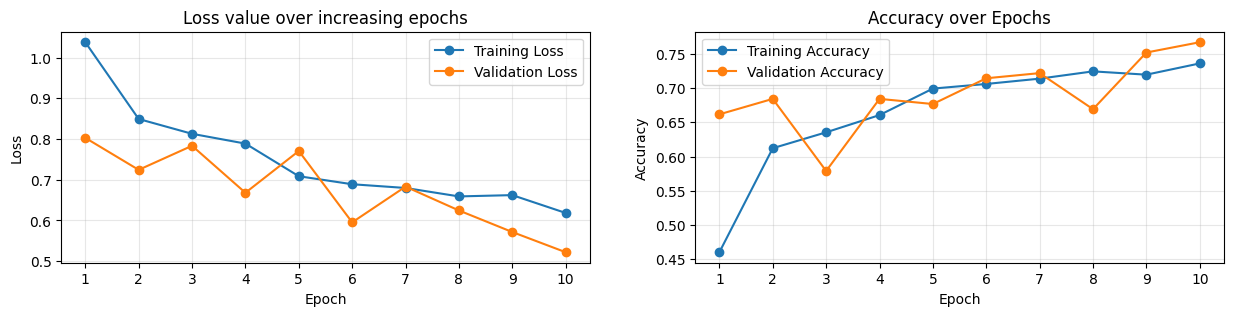

In [ ]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))

plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

model.eval()
all_predictions = []
all_labels = []

with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)
        prediction = model(x)
        predicted_labels = prediction.argmax(-1).cpu().numpy()
        all_predictions.extend(predicted_labels)
        all_labels.extend(y.numpy())

test_accuracy = np.mean(np.array(all_predictions) == np.array(all_labels))
print(f"Test Accuracy: {test_accuracy*100:.2f}%")
print(classification_report(
    all_labels, all_predictions,
    target_names=label_names,
    zero_division=0
))

Test Accuracy: 80.47%
                   precision    recall  f1-score   support

angular_leaf_spot       0.78      0.88      0.83        43
        bean_rust       0.73      0.74      0.74        43
          healthy       0.94      0.79      0.86        42

         accuracy                           0.80       128
        macro avg       0.82      0.80      0.81       128
     weighted avg       0.81      0.80      0.81       128



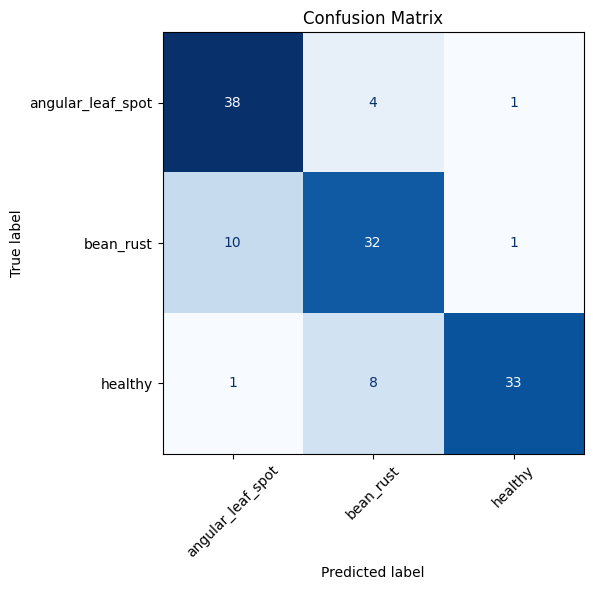

In [ ]:
cm = confusion_matrix(all_labels, all_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
torch.save(model.state_dict(), "beans_cnn_model.pth")
print("Model weights saved as beans_cnn_model.pth")

Model weights saved as beans_cnn_model.pth
